In [4]:
import pandas as pd

caminho_1 = "../../data/Corretiva Programada/Ordens do SAP -Corretiva programada (ZM02).XLSX"
caminho_2 = "../../data/Corretiva Programada/Ordens do SAP -Corretiva programada (ZM02)- 2.XLSX"

df_1 = pd.read_excel(caminho_1, sheet_name="Sheet1")
df_2 = pd.read_excel(caminho_2, sheet_name="Sheet1")

print("Arquivo 1:", df_1.shape)
print("Arquivo 2:", df_2.shape)
print("Mesmas colunas:", df_1.columns.equals(df_2.columns))

Arquivo 1: (1163, 28)
Arquivo 2: (1163, 28)
Mesmas colunas: True


In [5]:
df = df_1.copy()
print(f"Linhas: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

df.head()

Linhas: 1163
Colunas: 28


,Tipo de Nota,Nota,Ordem,Indisponível,Falha,IQM,Analisada,Comentários Classificação Engenharia,Perfil do catálogo,Descrição,...,Centro de Trabalho Responsável,Sintoma,Objeto,Defeito,Causa,Ação,Data Análise,Hora Análise,Encerram.por Data,Hora de Encerramento
0,Z2,15069252,54081268.0,NaN,NaN,NaN,NaN,NaN,6PSD,Porta PCC-PSD a,...,SP04IBUT,PDM NÃO ABRE,"ESTRUTURA, ACABAMENTO, E ACESSÓRIOS DO P",PORTA DESAJUSTADA,FALTA FIXACAO,FIXADO,NaT,00:00:00,2026-01-25,16:50:18
1,Z2,14647619,53659484.0,NaN,NaN,NaN,NaN,NaN,6PSD,PDMs plat 1 e 2 com falha momentânea.,...,SP04IBUT,MAU CONTATO,SWITCK DE COMUNICAÇÃO,SEM CONEXAO ELETRICA,ERRO DE SOFTWARE,RESETADO E TESTADO,NaT,00:00:00,2025-06-01,04:36:44
2,Z2,14682623,53694340.0,NaN,NaN,NaN,NaN,NaN,6PSD,Rele painel SSE intermitente,...,SP04IBUT,FACHADA PSD SEM ALIMENTAÇÃO,DISPOSITIVO DE PROTECAO,CONVERSOR DE TENSAO AVARIADO,OPERACAO INDEVIDA,SUBSTITUIDO(A),NaT,00:00:00,2025-06-19,05:10:12
3,Z2,14864269,53874165.0,NaN,NaN,NaN,NaN,NaN,6PSD,Multimedidor SSE moldura solta,...,SP04IBUT,ESTRUTURA DANIFICADA,MULTIMEDIDOR,VIDRO QUEBRADO,DESGASTE,SUBSTITUIDO(A),NaT,00:00:00,2025-09-30,14:53:22
4,Z2,13390549,52423535.0,NaN,NaN,NaN,NaN,NaN,6PSD,Volume do P.A baixo.,...,SP04IBUT,SERVIDOR SEM COMUNICACAO,SWITCK DE COMUNICAÇÃO,BAIXA ISOLACAO,FALTA FIXACAO,APERTADO(A),NaT,00:00:00,2023-07-27,13:52:02


In [6]:
print("Conteúdo exatamente igual:", df_1.equals(df_2))

Conteúdo exatamente igual: True


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1163 entries, 0 to 1162
Data columns (total 28 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   Tipo de Nota                          1163 non-null   str           
 1   Nota                                  1163 non-null   int64         
 2   Ordem                                 1158 non-null   float64       
 3   Indisponível                          1 non-null      str           
 4   Falha                                 0 non-null      float64       
 5   IQM                                   0 non-null      float64       
 6   Analisada                             1 non-null      str           
 7   Comentários Classificação Engenharia  1 non-null      str           
 8   Perfil do catálogo                    1163 non-null   str           
 9   Descrição                             1163 non-null   str           
 10  Local de In

In [8]:
relatorio_ausentes = pd.DataFrame({
    "quantidade": df.isna().sum(),
    "percentual": (df.isna().mean() * 100).round(2)
}).sort_values("percentual", ascending=False)

relatorio_ausentes[
    relatorio_ausentes["quantidade"] > 0
]

,quantidade,percentual
IQM,1163,100.00
Falha,1163,100.00
Indisponível,1162,99.91
Analisada,1162,99.91
Comentários Classificação Engenharia,1162,99.91
Data Análise,1162,99.91
Ação,43,3.70
Causa,42,3.61
Fim da avaria,39,3.35
Defeito,39,3.35


In [9]:
diagnostico_identificadores = pd.Series({
    "linhas": len(df),
    "notas_ausentes": df["Nota"].isna().sum(),
    "notas_distintas": df["Nota"].nunique(dropna=True),
    "notas_repetidas_excedentes": (
        df["Nota"].notna() & df["Nota"].duplicated()
    ).sum(),
    "ordens_ausentes": df["Ordem"].isna().sum(),
    "ordens_distintas": df["Ordem"].nunique(dropna=True),
    "ordens_repetidas_excedentes": (
        df["Ordem"].notna() & df["Ordem"].duplicated()
    ).sum(),
    "linhas_totalmente_duplicadas": df.duplicated().sum()
})

diagnostico_identificadores

linhas                          1163
notas_ausentes                     0
notas_distintas                 1158
notas_repetidas_excedentes         5
ordens_ausentes                    5
ordens_distintas                1153
ordens_repetidas_excedentes        5
linhas_totalmente_duplicadas       0
dtype: int64

In [12]:
colunas_criticas = [
    "Indisponível",
    "Falha",
    "IQM",
    "Analisada",
    "Comentários Classificação Engenharia",
    "Data Análise"
]

for coluna in colunas_criticas:
    print(f"\n--- {coluna} ---")
    print(df[coluna].value_counts(dropna=False))


--- Indisponível ---
Indisponível
NaN    1162
X         1
Name: count, dtype: int64

--- Falha ---
Falha
NaN    1163
Name: count, dtype: int64

--- IQM ---
IQM
NaN    1163
Name: count, dtype: int64

--- Analisada ---
Analisada
NaN    1162
X         1
Name: count, dtype: int64

--- Comentários Classificação Engenharia ---
Comentários Classificação Engenharia
NaN           1162
 NC/ RESET       1
Name: count, dtype: int64

--- Data Análise ---
Data Análise
NaT           1162
2026-03-04       1
Name: count, dtype: int64


In [13]:
df.loc[df["Ordem"].isna(), 
       ["Nota",
        "Ordem",
        "Descrição",
        "Local de Instalação",
        "Status do Usuário da Ordem",
        "Status do Sistema da Ordem",
        "Início avaria",
        "Fim da avaria"]]

,Nota,Ordem,Descrição,Local de Instalação,Status do Usuário da Ordem,Status do Sistema da Ordem,Início avaria,Fim da avaria
97,14795035,NaN,MCP PSD-FAL-PLT2-PP05PDM,SP04-6-PSD-FAL-PLT2-PP05PDM,NaN,NaN,22/08/2025,NaN
131,15037814,NaN,VENTILADOR CENTRIF 220W HOR R2E250RA4301,SP04-6-PSD-FAL-SLBT-PCC,NaN,NaN,08/01/2026,NaN
147,14363556,NaN,CONJUNTO COMPLETO DO TROLLEY PSD,SP04-6-PSD-FRA-PLT1-PP10PDM,NaN,NaN,29/12/2024,NaN
837,13327708,NaN,DOOR CONTROL MODULE-MCP,SP04-6-PSD-PIN-PLT2-PP06PDM,NaN,NaN,16/06/2023,16/06/2023
1028,13114749,NaN,DOOR CONTROL,SP04-6-PSD-REP-PLT1-PP16PDM,NaN,NaN,14/02/2023,NaN


In [14]:
df_limpo = df.copy()
df_limpo["linha_origem"] = df_limpo.index + 2

In [15]:
import re
import unicodedata

def normalizar_coluna(nome):
    nome = str(nome).strip().lower()
    nome = unicodedata.normalize("NFKD", nome)
    nome = nome.encode("ascii", "ignore").decode("ascii")
    nome = re.sub(r"[^a-z0-9]+", "_", nome)
    return nome.strip("_")

df_limpo.columns = [
    normalizar_coluna(coluna)
    for coluna in df_limpo.columns
]

print("Colunas duplicadas:", df_limpo.columns.duplicated().sum())
df_limpo.columns.tolist()

Colunas duplicadas: 0


['tipo_de_nota',
 'nota',
 'ordem',
 'indisponivel',
 'falha',
 'iqm',
 'analisada',
 'comentarios_classificacao_engenharia',
 'perfil_do_catalogo',
 'descricao',
 'local_de_instalacao',
 'status_do_usuario_da_ordem',
 'texto_longo_da_ordem',
 'status_do_sistema_da_ordem',
 'inicio_avaria',
 'hora_inicio_avaria',
 'fim_da_avaria',
 'hora_do_fim_da_avaria',
 'centro_de_trabalho_responsavel',
 'sintoma',
 'objeto',
 'defeito',
 'causa',
 'acao',
 'data_analise',
 'hora_analise',
 'encerram_por_data',
 'hora_de_encerramento',
 'linha_origem']

In [16]:
for coluna in ["nota", "ordem"]:
    df_limpo[coluna] = (
        df_limpo[coluna]
        .astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

df_limpo[["nota", "ordem"]].dtypes

nota     string
ordem    string
dtype: object

In [17]:
colunas_totalmente_vazias = [
    coluna
    for coluna in df_limpo.columns
    if df_limpo[coluna].isna().all()
]

colunas_totalmente_vazias

['falha', 'iqm']

In [18]:
df_limpo.drop(
    columns=colunas_totalmente_vazias,
    inplace=True
)

In [19]:
def converter_data(serie):
    if pd.api.types.is_datetime64_any_dtype(serie):
        return pd.to_datetime(serie, errors="coerce")

    numeros = pd.to_numeric(serie, errors="coerce")
    valores_numericos = numeros.notna()

    datas_texto = pd.to_datetime(
        serie.where(~valores_numericos),
        errors="coerce",
        dayfirst=True
    )

    datas_excel = pd.to_datetime(
        numeros.where(valores_numericos),
        errors="coerce",
        unit="D",
        origin="1899-12-30"
    )

    return datas_texto.fillna(datas_excel)

In [20]:
colunas_data = [
    "inicio_avaria",
    "fim_da_avaria",
    "data_analise",
    "encerram_por_data"
]

for coluna in colunas_data:
    valores_originais = df_limpo[coluna].copy()
    datas_convertidas = converter_data(valores_originais)

    invalidas = valores_originais.notna() & datas_convertidas.isna()

    df_limpo[coluna] = datas_convertidas

    print(f"{coluna}: {invalidas.sum()} valores inválidos")

inicio_avaria: 0 valores inválidos
fim_da_avaria: 0 valores inválidos
data_analise: 0 valores inválidos
encerram_por_data: 0 valores inválidos


In [21]:
for coluna in colunas_data:
    print(
        coluna,
        "| ausentes:", df_limpo[coluna].isna().sum(),
        "| mínima:", df_limpo[coluna].min(),
        "| máxima:", df_limpo[coluna].max()
    )

inicio_avaria | ausentes: 0 | mínima: 2023-01-03 00:00:00 | máxima: 2026-03-28 00:00:00
fim_da_avaria | ausentes: 39 | mínima: 2023-01-07 00:00:00 | máxima: 2026-05-14 00:00:00
data_analise | ausentes: 1162 | mínima: 2026-03-04 00:00:00 | máxima: 2026-03-04 00:00:00
encerram_por_data | ausentes: 7 | mínima: 2023-01-07 00:00:00 | máxima: 2026-05-14 00:00:00


In [22]:
from datetime import time

def converter_hora(valor):
    if pd.isna(valor):
        return pd.NaT

    # Horário já reconhecido pelo Excel/pandas
    if isinstance(valor, time):
        return pd.Timedelta(
            hours=valor.hour,
            minutes=valor.minute,
            seconds=valor.second
        )

    # Horário armazenado como fração de um dia
    try:
        numero = float(valor)

        if 0 <= numero < 1:
            return pd.to_timedelta(numero, unit="D")
    except (TypeError, ValueError):
        pass

    # Horário armazenado como texto
    horario = pd.to_datetime(
        str(valor),
        errors="coerce"
    )

    if pd.isna(horario):
        return pd.NaT

    return pd.Timedelta(
        hours=horario.hour,
        minutes=horario.minute,
        seconds=horario.second
    )

In [24]:
colunas_hora = [
    "hora_inicio_avaria",
    "hora_do_fim_da_avaria",
    "hora_analise",
    "hora_de_encerramento"
]

for coluna in colunas_hora:
    nova_coluna = f"{coluna}_convertida"

    df_limpo[nova_coluna] = (
        df_limpo[coluna].apply(converter_hora)
    )

    invalidos = (
        df_limpo[coluna].notna()
        & df_limpo[nova_coluna].isna()
    )

    print(
        f"{coluna}: {invalidos.sum()} horários inválidos"
    )

hora_inicio_avaria: 0 horários inválidos
hora_do_fim_da_avaria: 0 horários inválidos
hora_analise: 0 horários inválidos
hora_de_encerramento: 0 horários inválidos


In [26]:
df_limpo["inicio_avaria_datetime"] = (
    df_limpo["inicio_avaria"]
    + df_limpo["hora_inicio_avaria_convertida"]
)

df_limpo["fim_avaria_datetime"] = (
    df_limpo["fim_da_avaria"]
    + df_limpo["hora_do_fim_da_avaria_convertida"]
)

df_limpo["analise_datetime"] = (
    df_limpo["data_analise"]
    + df_limpo["hora_analise_convertida"]
)

df_limpo["encerramento_datetime"] = (
    df_limpo["encerram_por_data"]
    + df_limpo["hora_de_encerramento_convertida"]
)

In [27]:
colunas_datetime = [
    "inicio_avaria_datetime",
    "fim_avaria_datetime",
    "analise_datetime",
    "encerramento_datetime"
]

df_limpo[colunas_datetime].head()

,inicio_avaria_datetime,fim_avaria_datetime,analise_datetime,encerramento_datetime
0,2026-01-25 08:20:00,2026-01-25 09:30:00,NaT,2026-01-25 16:50:18
1,2025-05-30 09:30:00,2025-06-01 04:00:00,NaT,2025-06-01 04:36:44
2,2025-06-19 02:00:00,2025-06-19 04:30:00,NaT,2025-06-19 05:10:12
3,2025-09-30 09:00:00,2025-09-30 12:00:00,NaT,2025-09-30 14:53:22
4,2023-07-21 14:00:00,2023-07-27 13:50:56,NaT,2023-07-27 13:52:02


In [28]:
validacao_temporal = pd.Series({
    "inicio_ausente": (
        df_limpo["inicio_avaria_datetime"].isna().sum()
    ),
    "fim_ausente": (
        df_limpo["fim_avaria_datetime"].isna().sum()
    ),
    "analise_ausente": (
        df_limpo["analise_datetime"].isna().sum()
    ),
    "encerramento_ausente": (
        df_limpo["encerramento_datetime"].isna().sum()
    ),
    "fim_anterior_inicio": (
        df_limpo["fim_avaria_datetime"]
        < df_limpo["inicio_avaria_datetime"]
    ).sum(),
    "encerramento_anterior_inicio": (
        df_limpo["encerramento_datetime"]
        < df_limpo["inicio_avaria_datetime"]
    ).sum()
})

validacao_temporal

inicio_ausente                     0
fim_ausente                       39
analise_ausente                 1162
encerramento_ausente               7
fim_anterior_inicio                0
encerramento_anterior_inicio       0
dtype: int64

In [29]:
incoerencia_temporal = (
    (
        df_limpo["fim_avaria_datetime"]
        < df_limpo["inicio_avaria_datetime"]
    )
    |
    (
        df_limpo["encerramento_datetime"]
        < df_limpo["inicio_avaria_datetime"]
    )
)

df_limpo.loc[
    incoerencia_temporal,
    [
        "linha_origem",
        "nota",
        "ordem",
        "descricao",
        "inicio_avaria_datetime",
        "fim_avaria_datetime",
        "encerramento_datetime"
    ]
]

,linha_origem,nota,ordem,descricao,inicio_avaria_datetime,fim_avaria_datetime,encerramento_datetime


In [30]:
df_limpo["duracao_avaria_horas"] = (
    df_limpo["fim_avaria_datetime"]
    - df_limpo["inicio_avaria_datetime"]
).dt.total_seconds().div(3600)

In [31]:
df_limpo["duracao_avaria_horas"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
)

count     1124.000000
mean       486.409121
std       1221.026608
min          0.000000
50%         76.083333
90%       1338.900000
95%       2160.160833
99%       6104.705000
max      15107.333333
Name: duracao_avaria_horas, dtype: float64

In [32]:
def limpar_texto(serie, maiusculo=False):
    serie = (
        serie.astype("string")
        .str.replace("\u00a0", " ", regex=False)
        .str.replace(r"[ \t]+", " ", regex=True)
        .str.strip()
        .replace("", pd.NA)
    )

    if maiusculo:
        serie = serie.str.upper()

    return serie

In [33]:
colunas_categoricas = [
    "tipo_de_nota",
    "indisponivel",
    "analisada",
    "perfil_do_catalogo",
    "local_de_instalacao",
    "status_do_usuario_da_ordem",
    "status_do_sistema_da_ordem",
    "centro_de_trabalho_responsavel",
    "sintoma",
    "objeto",
    "defeito",
    "causa",
    "acao"
]

for coluna in colunas_categoricas:
    df_limpo[coluna] = limpar_texto(
        df_limpo[coluna],
        maiusculo=True
    )

In [34]:
colunas_descritivas = [
    "comentarios_classificacao_engenharia",
    "descricao",
    "texto_longo_da_ordem"
]

for coluna in colunas_descritivas:
    df_limpo[coluna] = limpar_texto(
        df_limpo[coluna]
    )

In [35]:
colunas_indicadoras = [
    "indisponivel",
    "analisada"
]

for coluna in colunas_indicadoras:
    df_limpo[f"{coluna}_flag"] = (
        df_limpo[coluna]
        .fillna("")
        .eq("X")
        .astype("boolean")
    )

In [36]:
for coluna in colunas_indicadoras:
    print(
        coluna,
        "| marcados:",
        df_limpo[coluna].eq("X").sum(),
        "| verdadeiros:",
        df_limpo[f"{coluna}_flag"].sum(),
        "| ausentes na flag:",
        df_limpo[f"{coluna}_flag"].isna().sum()
    )

indisponivel | marcados: 1 | verdadeiros: 1 | ausentes na flag: 0
analisada | marcados: 1 | verdadeiros: 1 | ausentes na flag: 0


In [37]:
colunas_dominio = [
    "tipo_de_nota",
    "perfil_do_catalogo",
    "indisponivel",
    "analisada",
    "centro_de_trabalho_responsavel",
    "sintoma",
    "objeto",
    "defeito",
    "causa",
    "acao"
]

resumo_categorias = pd.DataFrame({
    "preenchidos": [
        df_limpo[coluna].notna().sum()
        for coluna in colunas_dominio
    ],
    "ausentes": [
        df_limpo[coluna].isna().sum()
        for coluna in colunas_dominio
    ],
    "valores_unicos": [
        df_limpo[coluna].nunique(dropna=True)
        for coluna in colunas_dominio
    ]
}, index=colunas_dominio)

resumo_categorias

,preenchidos,ausentes,valores_unicos
tipo_de_nota,1163,0,1
perfil_do_catalogo,1163,0,1
indisponivel,1,1162,1
analisada,1,1162,1
centro_de_trabalho_responsavel,1163,0,14
sintoma,1163,0,57
objeto,1124,39,112
defeito,1124,39,92
causa,1121,42,21
acao,1120,43,9


In [38]:
for coluna in [
    "tipo_de_nota",
    "perfil_do_catalogo",
    "indisponivel",
    "analisada"
]:
    print(f"\n--- {coluna} ---")
    print(df_limpo[coluna].value_counts(dropna=False))


--- tipo_de_nota ---
tipo_de_nota
Z2    1163
Name: count, dtype: Int64

--- perfil_do_catalogo ---
perfil_do_catalogo
6PSD    1163
Name: count, dtype: Int64

--- indisponivel ---
indisponivel
<NA>    1162
X          1
Name: count, dtype: Int64

--- analisada ---
analisada
<NA>    1162
X          1
Name: count, dtype: Int64


In [39]:
colunas_comparacao = [
    normalizar_coluna(coluna)
    for coluna in df.columns
    if normalizar_coluna(coluna) not in ["falha", "iqm"]
]

colunas_comparacao

['tipo_de_nota',
 'nota',
 'ordem',
 'indisponivel',
 'analisada',
 'comentarios_classificacao_engenharia',
 'perfil_do_catalogo',
 'descricao',
 'local_de_instalacao',
 'status_do_usuario_da_ordem',
 'texto_longo_da_ordem',
 'status_do_sistema_da_ordem',
 'inicio_avaria',
 'hora_inicio_avaria',
 'fim_da_avaria',
 'hora_do_fim_da_avaria',
 'centro_de_trabalho_responsavel',
 'sintoma',
 'objeto',
 'defeito',
 'causa',
 'acao',
 'data_analise',
 'hora_analise',
 'encerram_por_data',
 'hora_de_encerramento']

In [40]:
notas_repetidas = df_limpo.loc[
    df_limpo["nota"].notna()
    & df_limpo["nota"].duplicated(keep=False)
].sort_values(["nota", "ordem"])

print("Linhas envolvidas:", len(notas_repetidas))
print(
    "Notas distintas repetidas:",
    notas_repetidas["nota"].nunique()
)

Linhas envolvidas: 10
Notas distintas repetidas: 5


In [41]:
notas_repetidas[
    [
        "linha_origem",
        "nota",
        "ordem",
        "descricao",
        "local_de_instalacao",
        "inicio_avaria_datetime",
        "fim_avaria_datetime"
    ]
]

,linha_origem,nota,ordem,descricao,local_de_instalacao,inicio_avaria_datetime,fim_avaria_datetime
789,791,13244110,52279352,Suporte do sensor quebrado,SP04-6-PSD-MBI-PLT2-PP21PDM,2023-04-29 12:10:00,2023-04-29 16:30:00
790,792,13244110,52279352,Suporte do sensor quebrado,SP04-6-PSD-MBI-PLT2-PP21PDM,2023-04-29 12:10:00,2023-04-29 16:30:00
160,162,13300540,52335058,Sensor PDM 20 Via 1 - Abertura de Porta,SP04-6-PSD-FRA-PLT1-PP20PDM,2023-05-31 22:00:00,2023-06-01 04:20:33
161,163,13300540,52335058,Sensor PDM 20 Via 1 - Abertura de Porta,SP04-6-PSD-FRA-PLT1-PP20PDM,2023-05-31 22:00:00,2023-06-01 04:20:33
1133,1135,13555757,52584827,PFP 2 PLATAFORMA 2 ABRINDO SOZINHA,SP04-6-PSD-VSO-PLT2-PFP2,2023-10-18 22:00:00,2023-10-19 04:15:11
1134,1136,13555757,52584827,PFP 2 PLATAFORMA 2 ABRINDO SOZINHA,SP04-6-PSD-VSO-PLT2-PFP2,2023-10-18 22:00:00,2023-10-19 04:15:11
540,542,14627759,53639844,Falha intermitente no sensor de abertura,SP04-6-PSD-HIG-PLT2-PP23PDM,2025-05-19 08:00:00,2025-05-19 11:00:00
541,543,14627759,53639844,Falha intermitente no sensor de abertura,SP04-6-PSD-HIG-PLT2-PP23PDM,2025-05-19 08:00:00,2025-05-19 11:00:00
978,980,14702528,53714669,Sensores de porta aberta/fechada.,SP04-6-PSD-PVS-VITE-PP01PDM,2025-07-01 03:15:00,2025-07-02 01:30:00
979,981,14702528,53714669,Sensores de porta aberta/fechada.,SP04-6-PSD-PVS-VITE-PP01PDM,2025-07-01 03:15:00,2025-07-02 01:30:00


In [42]:
ordens_repetidas = df_limpo.loc[
    df_limpo["ordem"].notna()
    & df_limpo["ordem"].duplicated(keep=False)
].sort_values(["ordem", "nota"])

print("Linhas envolvidas:", len(ordens_repetidas))
print(
    "Ordens distintas repetidas:",
    ordens_repetidas["ordem"].nunique()
)

Linhas envolvidas: 10
Ordens distintas repetidas: 5


In [43]:
ordens_repetidas[
    [
        "linha_origem",
        "nota",
        "ordem",
        "descricao",
        "inicio_avaria_datetime",
        "fim_avaria_datetime",
        "sintoma",
        "objeto",
        "defeito",
        "causa",
        "acao"
    ]
]

,linha_origem,nota,ordem,descricao,inicio_avaria_datetime,fim_avaria_datetime,sintoma,objeto,defeito,causa,acao
789,791,13244110,52279352,Suporte do sensor quebrado,2023-04-29 12:10:00,2023-04-29 16:30:00,CORREIA DE TRACAO AVARIADA,SENSOR PORTA FECHADA-HEADER BOX,SENSOR FECHADO DESAJUSTADO,FALTA FIXACAO,SUBSTITUIDO(A)
790,792,13244110,52279352,Suporte do sensor quebrado,2023-04-29 12:10:00,2023-04-29 16:30:00,CORREIA DE TRACAO AVARIADA,SENSOR PORTA FECHADA-HEADER BOX,SENSOR FECHADO DESAJUSTADO,<NA>,AJUSTADO(A)
160,162,13300540,52335058,Sensor PDM 20 Via 1 - Abertura de Porta,2023-05-31 22:00:00,2023-06-01 04:20:33,PSE/PFP/PTE NÃO ABRE,SENSOR PORTA ABERTA-HEADER BOX,SENSOR ABERTO AVARIADO,VIBRACAO,SUBSTITUIDO(A)
161,163,13300540,52335058,Sensor PDM 20 Via 1 - Abertura de Porta,2023-05-31 22:00:00,2023-06-01 04:20:33,PSE/PFP/PTE NÃO ABRE,SENSOR PORTA ABERTA-HEADER BOX,SENSOR ABERTO AVARIADO,DESGASTE,SUBSTITUIDO(A)
1133,1135,13555757,52584827,PFP 2 PLATAFORMA 2 ABRINDO SOZINHA,2023-10-18 22:00:00,2023-10-19 04:15:11,PSE/PFP/PTE NÃO INDICA FECHADA,"ESTRUTURA, ACABAMENTOS DA PFP",ATUADOR DA TRAVA DE PDM DESAJUSTADO,FALTA FIXACAO,FIXADO
1134,1136,13555757,52584827,PFP 2 PLATAFORMA 2 ABRINDO SOZINHA,2023-10-18 22:00:00,2023-10-19 04:15:11,PSE/PFP/PTE NÃO INDICA FECHADA,"ESTRUTURA, ACABAMENTOS DA PFP",ATUADOR DA TRAVA DE PDM DESAJUSTADO,<NA>,AJUSTADO(A)
540,542,14627759,53639844,Falha intermitente no sensor de abertura,2025-05-19 08:00:00,2025-05-19 11:00:00,PDM NÃO INDICA ABERTA,SENSOR PORTA ABERTA-HEADER BOX,SENSOR ABERTO AVARIADO,DESGASTE,SUBSTITUIDO(A)
541,543,14627759,53639844,Falha intermitente no sensor de abertura,2025-05-19 08:00:00,2025-05-19 11:00:00,PDM NÃO INDICA ABERTA,SENSOR PORTA FECHADA-HEADER BOX,SENSOR FECHADO AVARIADO,DESGASTE,SUBSTITUIDO(A)
978,980,14702528,53714669,Sensores de porta aberta/fechada.,2025-07-01 03:15:00,2025-07-02 01:30:00,PDM NÃO INDICA FECHADA,SENSOR PORTA ABERTA-HEADER BOX,SERVIDOR AVARIADO,ESMAGADO,SUBSTITUIDO(A)
979,981,14702528,53714669,Sensores de porta aberta/fechada.,2025-07-01 03:15:00,2025-07-02 01:30:00,PDM NÃO INDICA FECHADA,SENSOR PORTA FECHADA-HEADER BOX,SERVIDOR AVARIADO,ESMAGADO,SUBSTITUIDO(A)


In [44]:
duplicatas_exatas = df_limpo.loc[
    df_limpo.duplicated(
        subset=colunas_comparacao,
        keep=False
    )
].sort_values(["ordem", "nota"])

print(
    "Linhas envolvidas em duplicatas exatas:",
    len(duplicatas_exatas)
)

print(
    "Duplicatas exatas excedentes:",
    df_limpo.duplicated(
        subset=colunas_comparacao,
        keep="first"
    ).sum()
)

Linhas envolvidas em duplicatas exatas: 0
Duplicatas exatas excedentes: 0


In [46]:
colunas_sem_ordem = [
    coluna
    for coluna in colunas_comparacao
    if coluna != "ordem"
]

comparacao_ordens = (
    ordens_repetidas
    .groupby("ordem")[colunas_sem_ordem]
    .nunique(dropna=False)
)

divergencias_por_ordem = comparacao_ordens.apply(
    lambda linha: linha[linha > 1].index.tolist(),
    axis=1
)

divergencias_por_ordem = divergencias_por_ordem[
    divergencias_por_ordem.str.len() > 0
]

divergencias_por_ordem

ordem
52279352        [causa, acao]
52335058              [causa]
52584827        [causa, acao]
53639844    [objeto, defeito]
53714669             [objeto]
dtype: object

In [47]:
ordem_escolhida = divergencias_por_ordem.index[0]
colunas_divergentes = divergencias_por_ordem.loc[
    ordem_escolhida
]

df_limpo.loc[
    df_limpo["ordem"].eq(ordem_escolhida),
    ["linha_origem", "ordem"] + colunas_divergentes
].T

,789,790
linha_origem,791,792
ordem,52279352,52279352
causa,FALTA FIXACAO,<NA>
acao,SUBSTITUIDO(A),AJUSTADO(A)


In [48]:
notas_por_ordem = (
    ordens_repetidas
    .groupby("ordem")["nota"]
    .nunique()
)

ordens_por_nota = (
    notas_repetidas
    .groupby("nota")["ordem"]
    .nunique(dropna=True)
)

print("Quantidade de notas por ordem:")
print(notas_por_ordem.value_counts().sort_index())

print("\nQuantidade de ordens por nota:")
print(ordens_por_nota.value_counts().sort_index())

Quantidade de notas por ordem:
nota
1    5
Name: count, dtype: int64

Quantidade de ordens por nota:
ordem
1    5
Name: count, dtype: int64


In [49]:
df_limpo["ordem_ausente_flag"] = (
    df_limpo["ordem"].isna()
)

df_limpo["ordem_repetida_flag"] = (
    df_limpo["ordem"].notna()
    & df_limpo["ordem"].duplicated(keep=False)
)

df_limpo["nota_repetida_flag"] = (
    df_limpo["nota"].notna()
    & df_limpo["nota"].duplicated(keep=False)
)

In [50]:
df_limpo[
    [
        "ordem_ausente_flag",
        "ordem_repetida_flag",
        "nota_repetida_flag"
    ]
].sum()

ordem_ausente_flag      5
ordem_repetida_flag    10
nota_repetida_flag     10
dtype: int64

In [51]:
decisoes_limpeza = {
    "falha": "Removida por conter 100% de valores ausentes.",
    "iqm": "Removida por conter 100% de valores ausentes.",
    "duplicatas": (
        "Nenhuma duplicata exata encontrada após a limpeza."
    ),
    "ordens_repetidas": (
        "Cinco ordens repetidas foram mantidas porque apresentam "
        "divergências em campos técnicos."
    ),
    "ordens_ausentes": (
        "Cinco registros sem ordem foram mantidos por possuírem "
        "nota, descrição e localização."
    ),
    "valores_ausentes": (
        "As ausências foram preservadas sem imputação."
    )
}

In [52]:
duracoes = df_limpo[
    "duracao_avaria_horas"
].dropna()

q1 = duracoes.quantile(0.25)
q3 = duracoes.quantile(0.75)
iqr = q3 - q1

limite_iqr = q3 + 1.5 * iqr
limite_99 = duracoes.quantile(0.99)
limite_999 = duracoes.quantile(0.999)

limites_outliers = pd.Series({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "limite_IQR": limite_iqr,
    "percentil_99": limite_99,
    "percentil_99_9": limite_999,
    "máximo": duracoes.max()
})

limites_outliers

Q1                    8.187500
Q3                  359.125000
IQR                 350.937500
limite_IQR          885.531250
percentil_99       6104.705000
percentil_99_9    12741.833833
máximo            15107.333333
dtype: float64

In [53]:
pd.Series({
    "acima_limite_IQR": (
        duracoes > limite_iqr
    ).sum(),
    "acima_percentil_99": (
        duracoes > limite_99
    ).sum(),
    "acima_percentil_99_9": (
        duracoes > limite_999
    ).sum(),
    "duracao_zero": (
        duracoes == 0
    ).sum()
})

acima_limite_IQR        161
acima_percentil_99       12
acima_percentil_99_9      2
duracao_zero              5
dtype: int64

In [54]:
maiores_duracoes = df_limpo.nlargest(
    20,
    "duracao_avaria_horas"
)[
    [
        "linha_origem",
        "nota",
        "ordem",
        "descricao",
        "inicio_avaria_datetime",
        "fim_avaria_datetime",
        "duracao_avaria_horas",
        "status_do_usuario_da_ordem",
        "status_do_sistema_da_ordem"
    ]
]

maiores_duracoes

,linha_origem,nota,ordem,descricao,inicio_avaria_datetime,fim_avaria_datetime,duracao_avaria_horas,status_do_usuario_da_ordem,status_do_sistema_da_ordem
230,232,13565674,52593179,PSD Server sem comunicação com o CCO,2023-10-12 13:10:00,2025-07-03 00:30:00,15107.333333,LIBO EXDO,ENTE CNPA CAPC DNAT NOLQ SCDM
808,810,13352092,52385663,PSD - PCC - Horario do CITEC divergentes,2023-06-30 05:40:00,2024-12-23 15:00:00,13017.333333,LIBO EXDO ANEX,ENTE CNPA CAPC DNAT NOLQ SCDM
1140,1142,13704060,52728706,PDM Vidro riscado,2024-01-08 02:30:00,2025-04-01 04:00:00,10777.500000,LIBO ANEX,ENTE CNPA CAPC DNAT NOLQ SCDM
30,32,14318073,53333242,Miolo da maçaneta,2024-12-04 03:31:00,2026-02-06 04:00:00,10296.483333,LIBO EXDO,ENTE CNPA CAPC MATF MOME NOLQ
1141,1143,13704058,52728669,PDM Vidro riscado,2024-01-08 02:30:00,2024-12-16 04:00:00,8233.500000,LIBO EXDO ANEX,ENTE CNPA CAPC DNAT NOLQ SCDM
1146,1148,13704053,52728667,PSE Vidro riscado,2024-01-08 02:30:00,2024-12-16 04:00:00,8233.500000,LIBO EXDO ANEX,ENTE CNPA CAPC DNAT NOLQ SCDM
968,970,14511892,53525329,PSD Server sem comunicação com o SCL,2025-03-15 15:35:07,2026-01-30 04:00:00,7692.414722,LIBO EXDO PDTI,ENTE CNPA CAPC NOLQ SCDM
27,29,14473647,53486367,Escova da PDM,2025-02-22 00:36:17,2025-12-31 03:33:09,7490.947778,LIBO EXDO,ENTE CNPA CAPC MOME NOLQ
598,600,14302984,53318174,PSE08 - não fecha 45°,2024-11-26 03:40:00,2025-08-26 04:00:00,6552.333333,LIBO EXDO,ENTE CNPA CAPC MATF MOME NOLQ
596,598,14304638,53319832,PSE04 - Pino de travamento inoperante,2024-11-27 03:00:00,2025-08-18 04:00:00,6337.000000,LIBO EXDO,ENTE CNPA CAPC NOLQ SCDM


C:\Users\Inteli\AppData\Local\Temp\ipykernel_23252\1069454623.py:31: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(


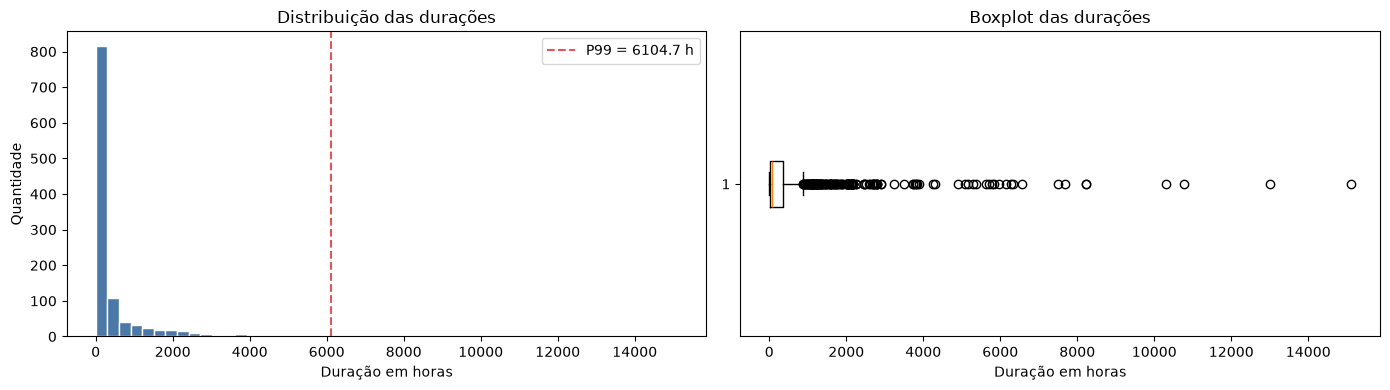

In [55]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 4)
)

axes[0].hist(
    duracoes,
    bins=50,
    color="#4C78A8",
    edgecolor="white"
)

axes[0].axvline(
    limite_99,
    color="#E15759",
    linestyle="--",
    label=f"P99 = {limite_99:.1f} h"
)

axes[0].set(
    title="Distribuição das durações",
    xlabel="Duração em horas",
    ylabel="Quantidade"
)

axes[0].legend()

axes[1].boxplot(
    duracoes,
    vert=False
)

axes[1].set(
    title="Boxplot das durações",
    xlabel="Duração em horas"
)

plt.tight_layout()
plt.show()

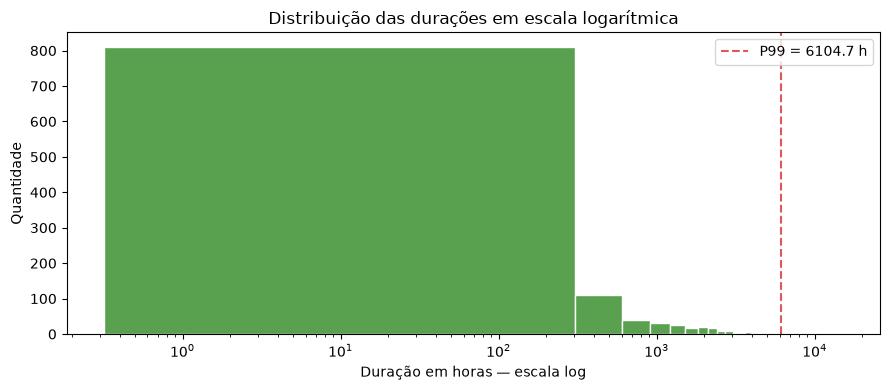

In [56]:
duracoes_positivas = duracoes[
    duracoes > 0
]

plt.figure(figsize=(9, 4))

plt.hist(
    duracoes_positivas,
    bins=50,
    color="#59A14F",
    edgecolor="white"
)

plt.xscale("log")

plt.axvline(
    limite_99,
    color="#E15759",
    linestyle="--",
    label=f"P99 = {limite_99:.1f} h"
)

plt.title(
    "Distribuição das durações em escala logarítmica"
)
plt.xlabel("Duração em horas — escala log")
plt.ylabel("Quantidade")
plt.legend()
plt.tight_layout()
plt.show()